EDA: Related to question 1: Can property characteristics predict sale prices more accurately than neighborhood-level price estimates?

In [17]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

df = train_data_df.copy()
df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
df['TotalBath'] = df['FullBath'] + 0.5*df['HalfBath'] + df['BsmtFullBath'] + 0.5*df['BsmtHalfBath']
df['HouseAgeAtSale'] = df['YrSold'] - df['YearBuilt']

# NaN in these text columns means "feature absent"
txt = df.select_dtypes(exclude=['number', 'category']).columns
df[txt] = df[txt].fillna('None')

df['QualTier'] = pd.cut(df['OverallQual'], [0,4,6,8,10],
                        labels=['Low (1-4)','Average (5-6)','Good (7-8)','Excellent (9-10)'])
df['SizeTier'] = pd.qcut(df['TotalSF'], 3, labels=['Small','Medium','Large'])


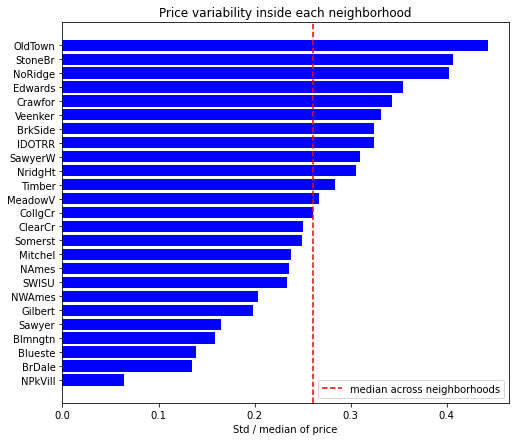

In [18]:
nb = df.groupby('Neighborhood')['SalePrice'].agg(['median','std','count'])
nb['CV'] = nb['std'] / nb['median']
nb = nb.sort_values('CV')

plt.figure(figsize=(8,7))
plt.barh(nb.index, nb['CV'], color='blue')
plt.axvline(nb['CV'].median(), color='red', ls='--', label='median across neighborhoods')
plt.xlabel('Std / median of price'); plt.legend()
plt.title('Price variability inside each neighborhood')
plt.show()

Long bar means homes in that neighborhood have widely different prices, so one neighborhood median describes them poorly.
Helps answer Q1: these are the neighborhoods where neighborhood-level estimates are least reliable and property-level review matters most. Short bars show where a neighborhood estimate is adequate.

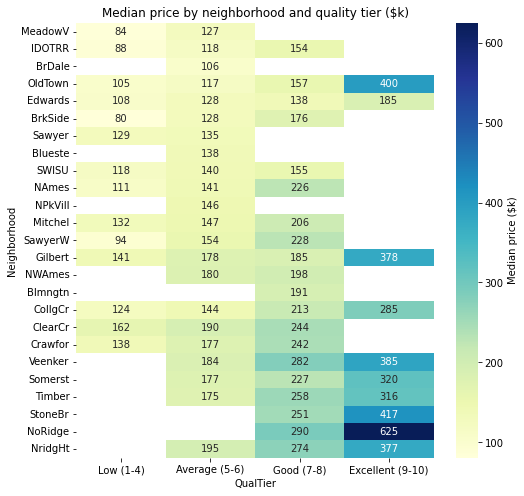

In [19]:
pt = df.pivot_table(index='Neighborhood', columns='QualTier',
                    values='SalePrice', aggfunc='median', observed=True)
pt = pt.loc[df.groupby('Neighborhood')['SalePrice'].median().sort_values().index]
plt.figure(figsize=(8,8))
sns.heatmap(pt / 1000, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': 'Median price ($k)'})
plt.title('Median price by neighborhood and quality tier ($k)')
plt.show()

In [20]:
read each row left to right. That’s one neighborhood, with quality rising. Blank cells mean no homes of that type exist there.
Helps answer Q1: if prices climb steeply across a single row, quality moves price substantially even when location is held fixed.
A neighborhood median hides that entirely.

SyntaxError: invalid syntax (3422007840.py, line 1)

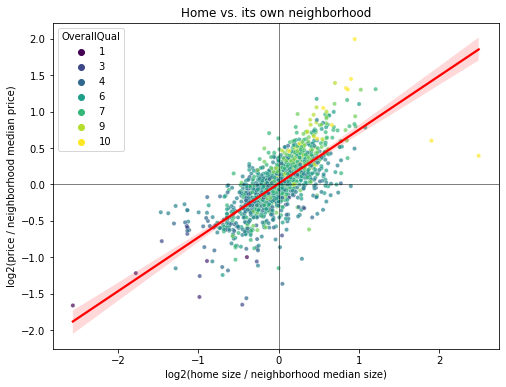

Correlation: 0.72


In [ ]:
df['RelPrice'] = df['SalePrice'] / df.groupby('Neighborhood')['SalePrice'].transform('median')
df['RelSF'] = df['TotalSF'] / df.groupby('Neighborhood')['TotalSF'].transform('median')

plt.figure(figsize=(8,6))
sns.scatterplot(x=np.log2(df['RelSF']), y=np.log2(df['RelPrice']),
                hue=df['OverallQual'], palette='viridis', s=18, alpha=0.7)
sns.regplot(x=np.log2(df['RelSF']), y=np.log2(df['RelPrice']), scatter=False, color='red')
plt.axhline(0, color='k', lw=0.5); plt.axvline(0, color='k', lw=0.5)
plt.xlabel('log2(home size / neighborhood median size)')
plt.ylabel('log2(price / neighborhood median price)')
plt.title('Home vs. its own neighborhood')
plt.show()
print('Correlation:', round(np.log2(df['RelSF']).corr(np.log2(df['RelPrice'])), 2))

each point is a home measured against its own neighborhood. 0 means exactly typical. The upward slope plus the color gradient show that larger and higher-quality homes sit above their neighborhood price.
Helps answer Q1: this strips location out completely. The remaining pattern is what property characteristics add on top of neighborhood. It helps assessors flag homes whose price departs from what their size and quality imply.

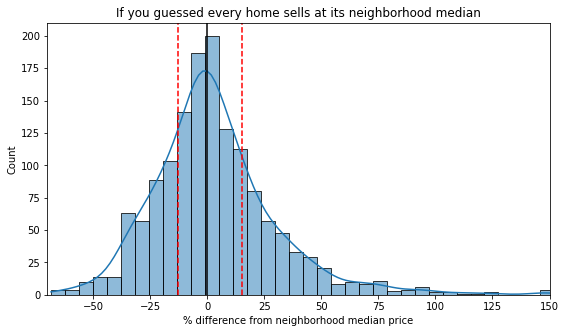

Typical miss (median absolute % error): 14.1 %
Share of homes missed by more than 20%: 36.3 %


In [ ]:
nb_med = df.groupby('Neighborhood')['SalePrice'].transform('median')
df['NbPctErr'] = (df['SalePrice'] - nb_med) / nb_med * 100   # % above/below neighborhood median

plt.figure(figsize=(9,5))
sns.histplot(df['NbPctErr'], bins=60, kde=True)
plt.axvline(0, color='k')
for p in [25, 75]:
    plt.axvline(df['NbPctErr'].quantile(p/100), color='red', ls='--')
plt.xlabel('% difference from neighborhood median price'); plt.xlim(-70, 150)
plt.title('If you guessed every home sells at its neighborhood median')
plt.show()
print('Typical miss (median absolute % error):', round(df['NbPctErr'].abs().median(), 1), '%')
print('Share of homes missed by more than 20%:', round((df['NbPctErr'].abs() > 20).mean()*100, 1), '%')

the distribution of how far each home’s actual price is from its neighborhood median, as a percent. Red dashed lines mark the middle 50% of homes.
Helps answer Q1: this is the baseline error of neighborhood-level estimates. A wide spread means that estimate often misses by a lot, which is the room property characteristics have to improve on. The printed numbers give you a headline figure for the write-up.

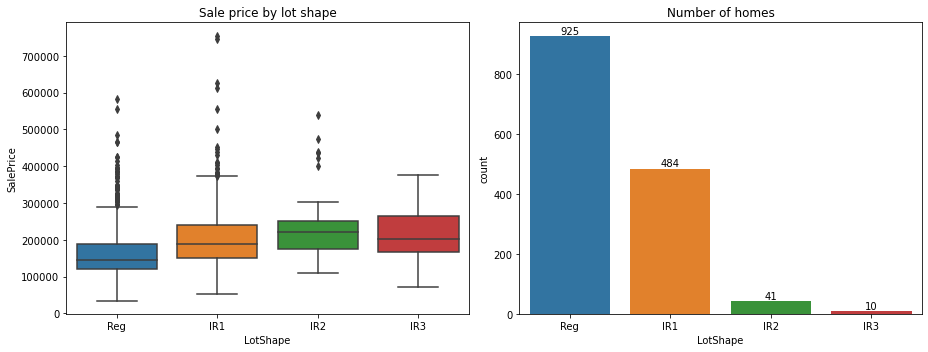

In [ ]:
order = ['Reg', 'IR1', 'IR2', 'IR3']
fig, axes = plt.subplots(1, 2, figsize=(13,5))
sns.boxplot(data=df, x='LotShape', y='SalePrice', order=order, ax=axes[0])
axes[0].set_title('Sale price by lot shape')
sns.countplot(data=df, x='LotShape', order=order, ax=axes[1])
axes[1].set_title('Number of homes')
for p in axes[1].patches:
    axes[1].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.tight_layout(); plt.show()

the price distribution for each shape.how many homes are in each.
Helps answer Q1: the raw gap between regular and irregular lots. The count panel tells you how much to trust each box. IR3 is tiny, so ignore its pattern.

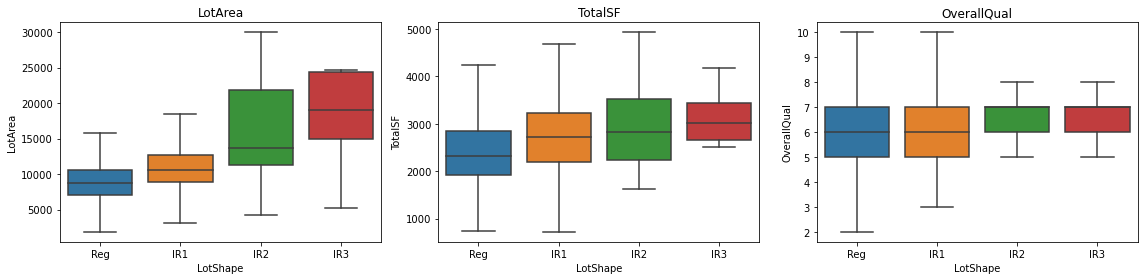

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
for ax, c in zip(axes, ['LotArea', 'TotalSF', 'OverallQual']):
    sns.boxplot(data=df, x='LotShape', y=c, order=order, showfliers=False, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

lot size, house size and quality by lot shape.
Helps: if irregular lots are higher on these, the price gap is likely explained by size and quality instead of by the shape.